In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

file_path = r"C:\Users\stefa\Desktop\BOOTCAMP\LABS\lab-eda-univariate\amz_uk_price_prediction_dataset.csv.zip"

df = pd.read_csv(file_path, compression="zip")

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [2]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])

crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [3]:
category_totals = crosstab.sum(axis=1)

best_seller_percentage = crosstab[True] / category_totals * 100

best_seller_percentage = best_seller_percentage.sort_values(ascending=False)

best_seller_percentage.head(10)

category
Grocery                           5.813467
Smart Home Security & Lighting    5.769231
Health & Personal Care            5.768628
Mobile Phone Accessories          4.247104
Power & Hand Tools                3.533895
Billiard, Snooker & Pool          3.212851
Pet Supplies                      3.020028
Home Brewing & Wine Making        2.845528
Mirrors                           2.800000
Wind Instruments                  2.800000
dtype: float64

In [4]:
chi2, p_value, dof, expected = st.chi2_contingency(crosstab)

print("Chi-square:", chi2)
print("P-value:", p_value)

Chi-square: 36540.20270061387
P-value: 0.0


In [5]:
total_rows = crosstab.sum().sum()

minimum_dimension = min(crosstab.shape) - 1

cramers_v = np.sqrt(chi2 / (total_rows * minimum_dimension))

print("Cramer's V:", cramers_v)

Cramer's V: 0.1222829439760564


In [6]:
top_10_categories = df["category"].value_counts().head(10).index

top_10_data = df[df["category"].isin(top_10_categories)]

top_10_crosstab = pd.crosstab(
    top_10_data["category"],
    top_10_data["isBestSeller"]
)

top_10_crosstab

isBestSeller,False,True
category,,
Bath & Body,19059,33
Beauty,19010,302
Birthday Gifts,18943,35
Fragrances,18550,14
Hair Care,18665,70
"Handmade Clothing, Shoes & Accessories",19215,14
Make-up,18715,41
Manicure & Pedicure Products,18882,58
Skin Care,18711,58


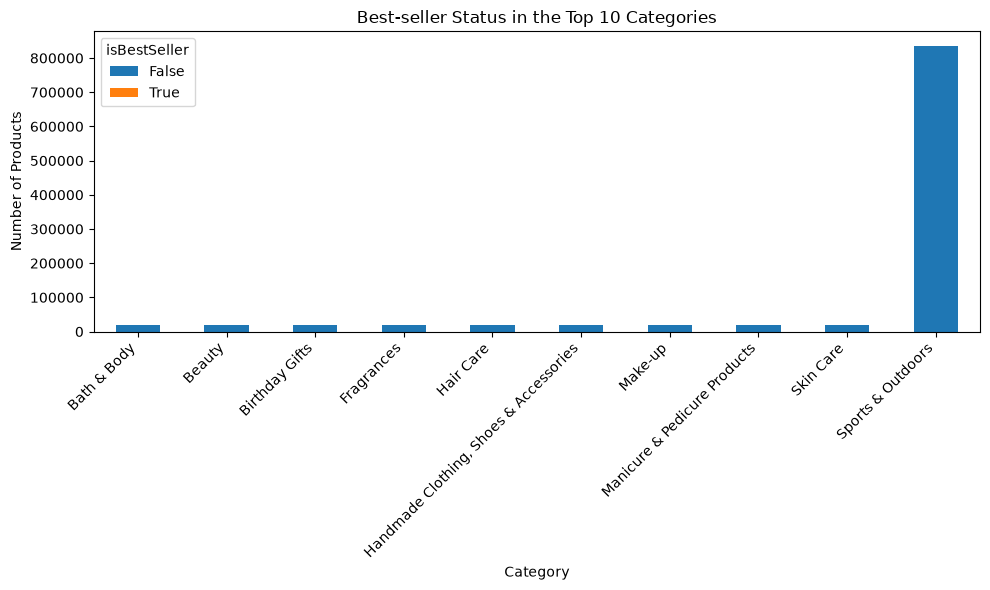

In [7]:
top_10_crosstab.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Best-seller Status in the Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
q1 = df["price"].quantile(0.25)

q3 = df["price"].quantile(0.75)

iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr

upper_limit = q3 + 1.5 * iqr

In [9]:
df_clean = df[
    (df["price"] >= lower_limit)
    & (df["price"] <= upper_limit)
]

print("Original rows:", len(df))
print("Rows without price outliers:", len(df_clean))

Original rows: 2443651
Rows without price outliers: 2115963


In [10]:
top_20_categories = df_clean["category"].value_counts().head(20).index

df_top_20 = df_clean[df_clean["category"].isin(top_20_categories)]

In [11]:
top_20_categories = df_clean["category"].value_counts().head(20).index

df_top_20 = df_clean[df_clean["category"].isin(top_20_categories)]

In [12]:
median_prices = df_clean.groupby("category")["price"].median()

median_prices = median_prices.sort_values(ascending=False)

median_prices.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [13]:
top_10_categories = df_clean["category"].value_counts().head(10).index

df_top_10 = df_clean[df_clean["category"].isin(top_10_categories)]

average_prices = df_top_10.groupby("category")["price"].mean()

average_prices = average_prices.sort_values()

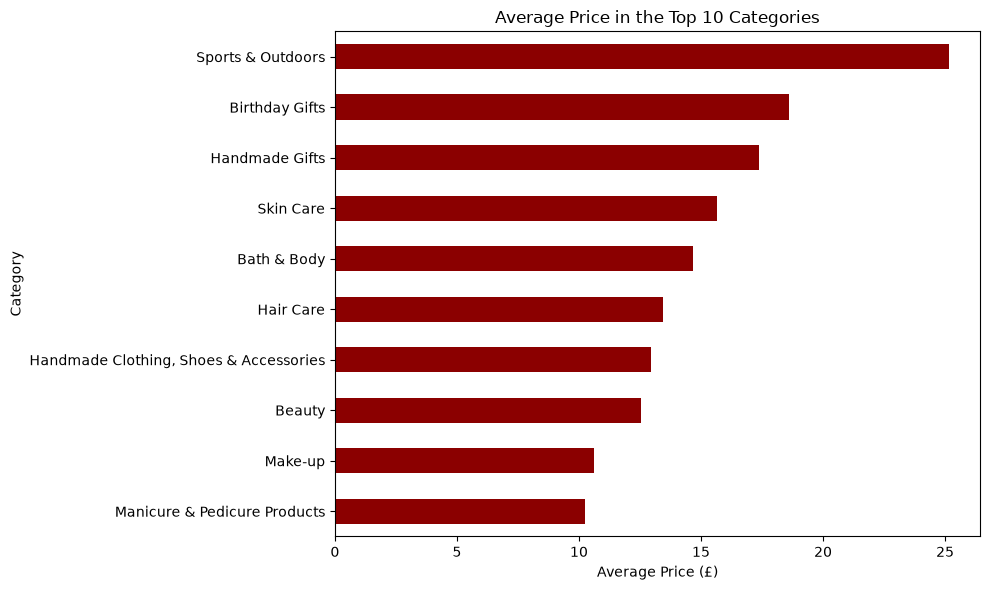

In [14]:
average_prices.plot(
    kind="barh",
    figsize=(10, 6),
    color="darkred"
)

plt.title("Average Price in the Top 10 Categories")
plt.xlabel("Average Price (£)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [15]:
all_average_prices = df_clean.groupby("category")["price"].mean()

all_average_prices = all_average_prices.sort_values(ascending=False)

all_average_prices.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

In [16]:
top_10_categories = df_clean["category"].value_counts().head(10).index

df_top_10 = df_clean[df_clean["category"].isin(top_10_categories)]

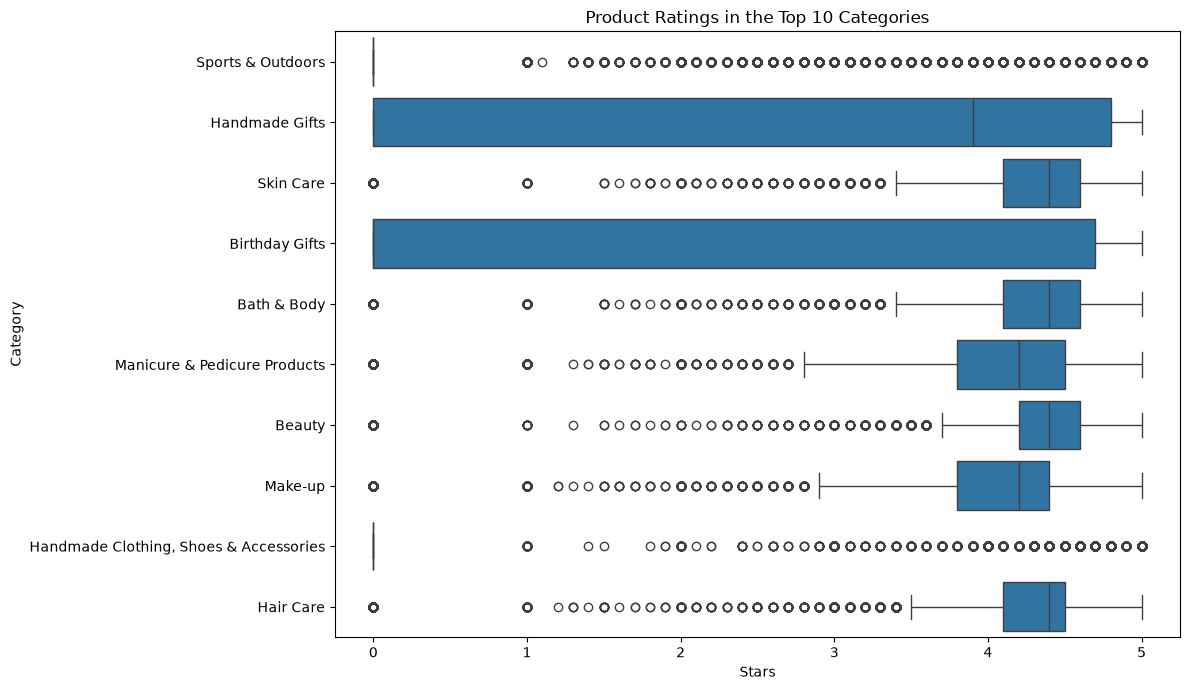

In [17]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df_top_10,
    x="stars",
    y="category"
)

plt.title("Product Ratings in the Top 10 Categories")
plt.xlabel("Stars")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [18]:
median_ratings = df_clean.groupby("category")["stars"].median()

median_ratings = median_ratings.sort_values(ascending=False)

median_ratings.head(10)

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

In [19]:
price_stars = df_clean[["price", "stars"]]

price_stars = price_stars.dropna()

correlation = price_stars["price"].corr(price_stars["stars"])

print("Correlation between price and stars:", correlation)

Correlation between price and stars: -0.07767299878181444


In [20]:
sample_data = price_stars.sample(100000, random_state=42)

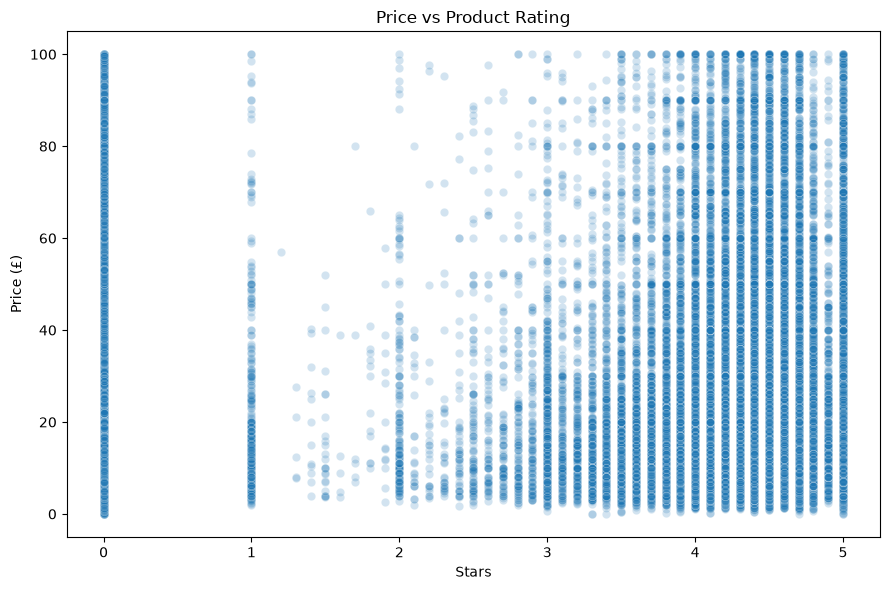

In [21]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=sample_data,
    x="stars",
    y="price",
    alpha=0.2
)

plt.title("Price vs Product Rating")
plt.xlabel("Stars")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()

In [22]:
numeric_columns = [
    "stars",
    "reviews",
    "price",
    "boughtInLastMonth"
]

correlation_table = df_clean[numeric_columns].corr()

correlation_table

,stars,reviews,price,boughtInLastMonth
stars,1.000000,0.083920,-0.077673,0.113994
reviews,0.083920,1.000000,-0.008498,0.105624
price,-0.077673,-0.008498,1.000000,-0.059051
boughtInLastMonth,0.113994,0.105624,-0.059051,1.000000


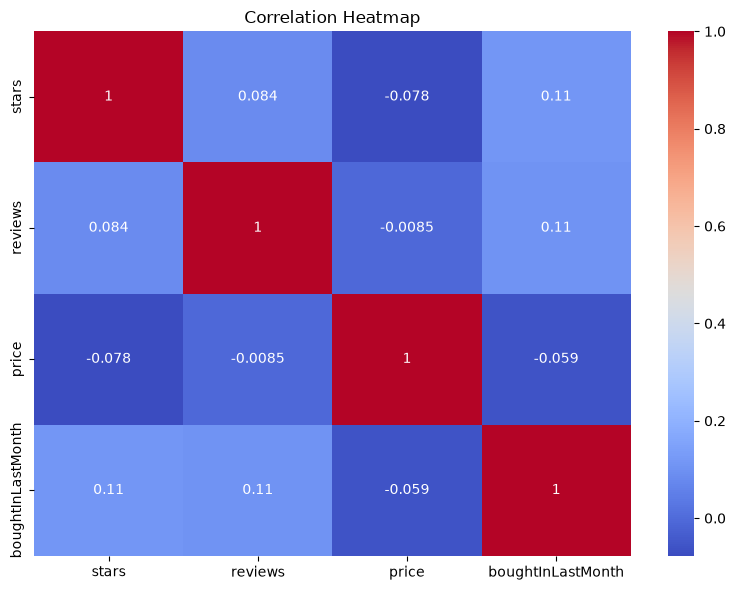

In [23]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_table,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

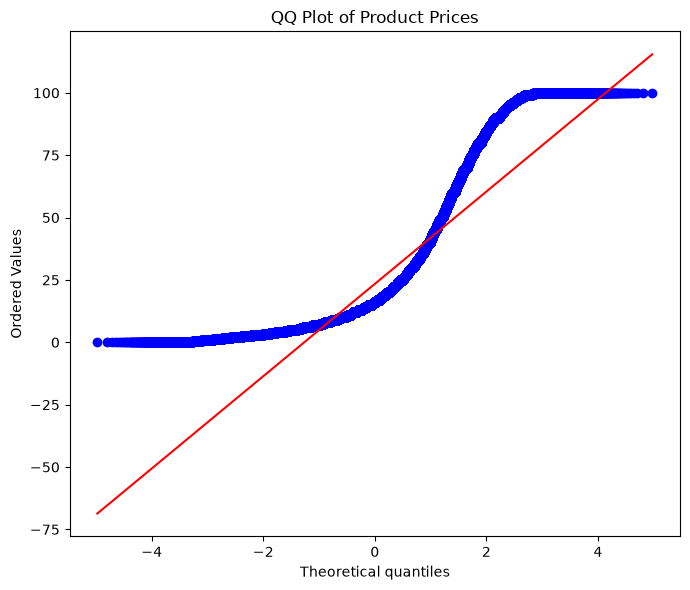

In [24]:
plt.figure(figsize=(7, 6))

st.probplot(
    df_clean["price"].dropna(),
    dist="norm",
    plot=plt
)

plt.title("QQ Plot of Product Prices")
plt.tight_layout()
plt.show()